# SARIMA — Previsão do Preço Mensal do Arroz

**TCC — Sistemas de Informação | PUCRS**  
Bruno Origem Noronha

Este notebook implementa o **SARIMA** como *baseline* estatístico univariado: usa **apenas** a coluna `preco_brl`.

Roteiro:
1. Carregamento e divisão dos dados (80% treino / 20% teste, em ordem cronológica)
2. Teste de estacionariedade (ADF)
3. Ajuste do modelo SARIMA
4. Previsão no teste e métricas (RMSE, MAE, MAPE)
5. Gráfico final: Real vs. Previsão

In [3]:
!python -m pip install statsmodels

  Using cached statsmodels-0.15.0-cp313-cp313-win_amd64.whl.metadata (9.6 kB)
  Using cached scipy-1.18.1-cp313-cp313-win_amd64.whl.metadata (61 kB)
  Using cached patsy-1.0.3-py2.py3-none-any.whl.metadata (3.7 kB)
  Using cached formulaic-1.2.2-py3-none-any.whl.metadata (7.0 kB)
  Using cached interface_meta-2.0.1-py3-none-any.whl.metadata (6.4 kB)
  Using cached narwhals-2.27.1-py3-none-any.whl.metadata (15 kB)
  Using cached wrapt-2.5.2rc1-cp313-cp313-win_amd64.whl.metadata (7.7 kB)
Using cached statsmodels-0.15.0-cp313-cp313-win_amd64.whl (11.3 MB)
Using cached formulaic-1.2.2-py3-none-any.whl (118 kB)
Using cached patsy-1.0.3-py2.py3-none-any.whl (233 kB)
Using cached scipy-1.18.1-cp313-cp313-win_amd64.whl (36.6 MB)
Using cached interface_meta-2.0.1-py3-none-any.whl (15 kB)
Using cached narwhals-2.27.1-py3-none-any.whl (483 kB)
Using cached wrapt-2.5.2rc1-cp313-cp313-win_amd64.whl (106 kB)



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
# Bibliotecas
import os
import warnings
warnings.filterwarnings("ignore")   # esconde avisos internos das bibliotecas, para a saída ficar limpa

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller           # teste de estacionariedade
from statsmodels.tsa.statespace.sarimax import SARIMAX   # modelo SARIMA

# Pasta onde salvamos o gráfico e as métricas
PASTA_SAIDA = "outputs"
os.makedirs(PASTA_SAIDA, exist_ok=True)

## 1. Carregamento e divisão dos dados

- Os preços originais são **diários**. Calculamos a **média de cada mês** (`resample("MS")`), pois o SARIMA trabalha bem com sazonalidade mensal (ciclo de 12 meses).
- A divisão é **cronológica**: os primeiros 80% dos meses viram treino e os 20% finais viram teste. Nunca embaralhamos os dados, para o modelo não "ver o futuro".

In [5]:
# Lê o CSV e usa a coluna "data" como índice de tempo
df = pd.read_csv("../data/processed/preco_arroz_limpo.csv", parse_dates=["data"], index_col="data")

# Fica só com o preço em reais e transforma em média mensal
serie = df["preco_brl"].resample("MS").mean().dropna()

# Divisão 80% treino / 20% teste, respeitando a ordem do tempo
corte  = int(len(serie) * 0.80)
treino = serie.iloc[:corte]
teste  = serie.iloc[corte:]

print(f"Total : {len(serie)} meses ({serie.index[0]:%m/%Y} a {serie.index[-1]:%m/%Y})")
print(f"Treino: {len(treino)} meses ({treino.index[0]:%m/%Y} a {treino.index[-1]:%m/%Y})")
print(f"Teste : {len(teste)} meses ({teste.index[0]:%m/%Y} a {teste.index[-1]:%m/%Y})")

Total : 220 meses (01/2008 a 04/2026)
Treino: 176 meses (01/2008 a 08/2022)
Teste : 44 meses (09/2022 a 04/2026)


## 2. Teste de estacionariedade (ADF)

O SARIMA precisa de uma série **estacionária** (média e variância estáveis ao longo do tempo).
O teste **ADF (Dickey-Fuller Aumentado)** verifica isso:

- **H₀:** a série **não** é estacionária.
- **p-valor < 0,05** → rejeitamos H₀ → a série **é** estacionária.

Testamos a série original e a **primeira diferença** (variação de um mês para o outro). Usamos só o treino.

In [6]:
def teste_adf(s, nome):
    p_valor = adfuller(s)[1]   # o 2º item do resultado é o p-valor
    conclusao = "estacionária" if p_valor < 0.05 else "NÃO estacionária"
    print(f"{nome:<16} p-valor = {p_valor:.4f}  ->  {conclusao}")

teste_adf(treino, "Série original")
teste_adf(treino.diff().dropna(), "1ª diferença")

Série original   p-valor = 0.7249  ->  NÃO estacionária
1ª diferença     p-valor = 0.0000  ->  estacionária


**Leitura:** a série original não é estacionária, mas a 1ª diferença é. Por isso usamos **d = 1** (uma diferenciação) no modelo.

## 3. Ajuste do modelo SARIMA

O modelo é escrito como **SARIMA(p, d, q)(P, D, Q, s)**:

| Parâmetro | Valor | Significado |
|---|---|---|
| **p** | 2 | usa os preços dos **2 meses anteriores** (parte autorregressiva) |
| **d** | 1 | **1 diferenciação** para tornar a série estacionária (resultado do ADF) |
| **q** | 0 | sem termo de média móvel dos erros recentes |
| **P** | 1 | usa o preço do **mesmo mês do ano anterior** (autorregressivo sazonal) |
| **D** | 1 | **1 diferenciação sazonal** (compara cada mês com o mesmo mês do ano anterior) |
| **Q** | 1 | corrige pelo erro do **mesmo mês do ano anterior** (média móvel sazonal) |
| **s** | 12 | ciclo sazonal de **12 meses** (dados mensais) |

`d` e `s` vêm da análise acima. `p`, `q`, `P` e `Q` foram escolhidos pelo menor **AIC** (critério que equilibra ajuste e simplicidade) numa busca feita somente no treino.

O modelo é ajustado **apenas com o treino**.

In [7]:
ORDEM         = (2, 1, 0)       # (p, d, q)
ORDEM_SAZONAL = (1, 1, 1, 12)   # (P, D, Q, s)

modelo = SARIMAX(treino, order=ORDEM, seasonal_order=ORDEM_SAZONAL)
resultado = modelo.fit(disp=False)   # disp=False esconde as mensagens da otimização

print(resultado.summary())

                                      SARIMAX Results                                       
Dep. Variable:                            preco_brl   No. Observations:                  176
Model:             SARIMAX(2, 1, 0)x(1, 1, [1], 12)   Log Likelihood                -404.078
Date:                              Thu, 22 Oct 2026   AIC                            818.157
Time:                                      12:03:26   BIC                            833.625
Sample:                                  01-01-2008   HQIC                           824.437
                                       - 08-01-2022                                         
Covariance Type:                                opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.6004      0.028     21.539      0.000       0.546       0.655
ar.L2         -0.34

## 4. Previsão no teste e métricas

O modelo prevê todos os meses do teste de uma só vez, sem ter visto nenhum deles (*out-of-sample*).
Também guardamos o **intervalo de confiança de 95%**, que mostra a incerteza da previsão.

| Métrica | O que mede |
|---|---|
| **RMSE** | raiz do erro quadrático médio, em R\$; pune mais os erros grandes |
| **MAE** | erro absoluto médio, em R\$; "em média, erramos X reais por mês" |
| **MAPE** | erro percentual médio; "em média, erramos X% do preço" |

In [8]:
# Previsão para o mesmo número de meses do teste
previsao  = resultado.get_forecast(steps=len(teste))
y_prev    = previsao.predicted_mean
intervalo = previsao.conf_int(alpha=0.05)   # limites inferior e superior (95%)

# Métricas calculadas diretamente pelas fórmulas
erro = teste - y_prev
rmse = np.sqrt(np.mean(erro ** 2))
mae  = np.mean(np.abs(erro))
mape = np.mean(np.abs(erro / teste)) * 100

print(f"RMSE = R$ {rmse:.2f}")
print(f"MAE  = R$ {mae:.2f}")
print(f"MAPE = {mape:.2f}%")

# Salva as métricas para a tabela comparativa com XGBoost e LSTM
pd.DataFrame({"modelo": ["SARIMA"], "RMSE": [rmse], "MAE": [mae], "MAPE": [mape]}) \
  .round(2).to_csv(f"{PASTA_SAIDA}/metricas_sarima.csv", index=False)

RMSE = R$ 24.51
MAE  = R$ 21.20
MAPE = 25.39%


## 5. Gráfico final: Real vs. Previsão

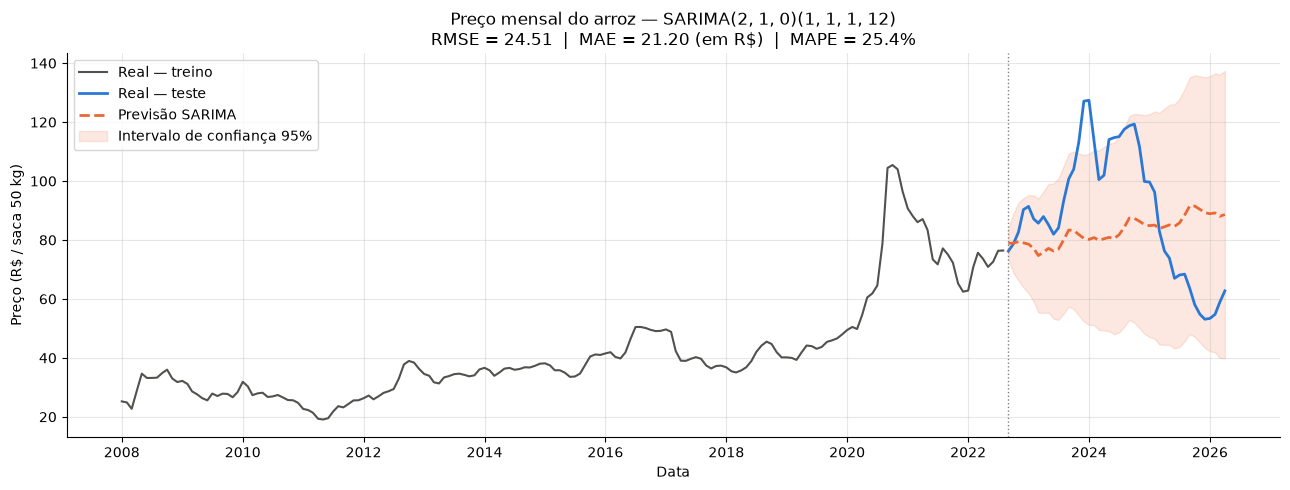

In [6]:
fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(treino, color="#52514e", lw=1.5, label="Real — treino")
ax.plot(teste,  color="#2a78d6", lw=2,   label="Real — teste")
ax.plot(y_prev, color="#eb6834", lw=2, ls="--", label="Previsão SARIMA")
ax.fill_between(intervalo.index, intervalo.iloc[:, 0], intervalo.iloc[:, 1],
                color="#eb6834", alpha=0.15, label="Intervalo de confiança 95%")
ax.axvline(teste.index[0], color="gray", ls=":", lw=1)   # linha do corte treino/teste

ax.set_title(f"Preço mensal do arroz — SARIMA{ORDEM}{ORDEM_SAZONAL}\n"
             f"RMSE = {rmse:.2f}  |  MAE = {mae:.2f} (em R$)  |  MAPE = {mape:.1f}%")
ax.set_xlabel("Data")
ax.set_ylabel("Preço (R$ / saca 50 kg)")
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper left")

plt.tight_layout()
plt.savefig(f"{PASTA_SAIDA}/sarima_previsao.png", dpi=150)
plt.show()